# M4: Null models

**Paper section covered:** 4.3 (Comparison with Null Models: Erdos-Renyi and Barabasi-Albert), Table 3, Figs. 7 to 10

## Goal
1. **Reproduce** the paper's comparison of the USFN with random (Erdos-Renyi, ER) and scale-free (Barabasi-Albert, BA) networks, including Table 3.
2. **Put error bars on it.** The paper compares against only three random graphs of each kind and quotes no uncertainty.
3. **Test the paper's interpretation** with a fairer null model, a *degree-preserving* rewiring that keeps every airport's number of connections but randomises who is connected to whom, and with a direct test of the paper's claim that geography shapes the network.

## What the paper does and claims
- Builds 3 ER graphs (same N = 541, p = 2m / (N(N-1))) and 3 BA graphs (N = 541) and compares clustering C, average path length L and the degree distribution (Table 3, Figs. 7 to 10).
- **ER:** shorter paths than the USFN, "suggesting the USFN was probably not designed for the shortest distance but was more of an economical design"; far lower clustering (0.02 vs 0.49), "suggesting the presence of communities that do not arise from random choice"; binomial degree distribution versus the USFN's heavy tail, so the network is non-random.
- **BA:** reproduces the heavy tail and the hubs but with shorter paths and much lower clustering (0.06), so BA "falls short in replicating the meaningful grouping of USFN".
- Conclusion: the airport network is "constrained by geography, policies, or other real-world constraints and is not random".

## Plan
| Part | Content |
|---|---|
| A | Reproduce Table 3 and Figs. 7 to 10 exactly |
| B | 200 samples of each null: mean, spread, z-scores |
| C | Degree-preserving null: how much of the paper's evidence is just the degree sequence? |
| D | Geography: do real routes really follow it? |
| E | Verdict on each claim |

## 1. Setup

In [1]:
import sys, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
import usfn
import nullmodels as nm

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 20)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
BLUE, RED, GREEN, ORANGE, GREY = "#3b6ea5", "#c05746", "#4d8f5b", "#d99a2b", "#777777"

airports, routes = usfn.load_openflights()
G = usfn.build_country_network(airports, routes)
N, M = G.number_of_nodes(), G.number_of_edges()
real = nm.fast_metrics(G)
assert (N, M) == (541, 2780) and abs(real["C"] - 0.4944) < 1e-3 and abs(real["L"] - 3.2) < 1e-3
print(f"USFN: N = {N}, M = {M}, C = {real['C']:.4f}, L = {real['L']:.4f}")

USFN: N = 541, M = 2780, C = 0.4944, L = 3.2000


## Part A. Reproducing the paper

### A1. Building the paper's null networks
- **ER:** `p = 2m / (N(N-1))` with the real N = 541 and m = 2780, so the expected number of edges equals the real one (actual counts fluctuate).
- **BA:** each new node attaches to `k` existing nodes. The paper reports 2,680 edges for every BA graph, which is exactly `k * (N - k)` for **k = 5** (5 x 536). So the BA parameter is k = round(M / N) = round(5.14) = 5, which cannot match the real edge count (BA edges come in multiples of k).
- The paper does not state the random seeds. We tried seeds 0, 1, 2 (the natural choice) and they reproduce the paper's edge counts exactly, as shown next.

In [2]:
er = [nm.er_like(N, M, seed=s) for s in range(3)]
ba = [nm.ba_like(N, M, seed=s) for s in range(3)]
k_ba = round(M / N)
print(f"ER probability p = {2 * M / (N * (N - 1)):.5f} | BA attachment k = {k_ba} (edges = k(N-k) = {k_ba * (N - k_ba)})")

paper_t3 = pd.DataFrame([
    ("Real Network",        541, 2780, 0.49, 3.20), ("Random ER Network 1", 541, 2767, 0.02, 2.95),
    ("Random ER Network 2", 541, 2777, 0.02, 2.94), ("Random ER Network 3", 541, 2832, 0.02, 2.92),
    ("Scale-Free BA Network 1", 541, 2680, 0.06, 2.80), ("Scale-Free BA Network 2", 541, 2680, 0.06, 2.80),
    ("Scale-Free BA Network 3", 541, 2680, 0.06, 2.78)], columns=["model", "nodes", "edges", "C", "L"])

graphs = [("Real Network", G)] + [(f"Random ER Network {i+1}", g) for i, g in enumerate(er)] + [(f"Scale-Free BA Network {i+1}", g) for i, g in enumerate(ba)]
ours = pd.DataFrame([{"model": n, **{k: v for k, v in nm.fast_metrics(g).items() if k in ("nodes", "edges", "C", "L")}} for n, g in graphs])

t3 = paper_t3.merge(ours, on="model", suffixes=(" paper", " ours"))
t3 = t3[["model", "nodes paper", "nodes ours", "edges paper", "edges ours", "C paper", "C ours", "L paper", "L ours"]]
t3.style.hide(axis="index").format({"C ours": "{:.4f}", "L ours": "{:.4f}", "C paper": "{:.2f}", "L paper": "{:.2f}"})

ER probability p = 0.01903 | BA attachment k = 5 (edges = k(N-k) = 2680)


model,nodes paper,nodes ours,edges paper,edges ours,C paper,C ours,L paper,L ours
Real Network,541,541,2780,2780,0.49,0.4944,3.20,3.2000
Random ER Network 1,541,541,2767,2767,0.02,0.0201,2.95,2.9504
Random ER Network 2,541,541,2777,2777,0.02,0.0170,2.94,2.9440
Random ER Network 3,541,541,2832,2832,0.02,0.0218,2.92,2.9230
Scale-Free BA Network 1,541,541,2680,2680,0.06,0.0613,2.80,2.7942
Scale-Free BA Network 2,541,541,2680,2680,0.06,0.0579,2.80,2.8025
Scale-Free BA Network 3,541,541,2680,2680,0.06,0.0680,2.78,2.7758


**Table 3 reproduces.** Node counts and every edge count (2767, 2777, 2832 and 2680 x 3) match exactly. For the three **ER** networks, clustering and path length match the paper to its two printed decimals, so seeds 0, 1, 2 are almost certainly what the paper used. For the **BA** networks every value is within 0.01 of the paper's (for example BA1: L = 2.794 vs 2.80; BA3: C = 0.068 vs 0.06). The tiny differences are most likely due to a different networkx version (the BA generator's starting graph has changed between releases) or to loose rounding in the paper; either way they are far smaller than the differences between models that the comparison is about.

### A2. Degree distributions (Figs. 7 and 9)
The paper overlays P(k) of the real network and of each null. We use linear axes (as the paper) and also log-log, because on linear axes the nulls squeeze into the left edge.

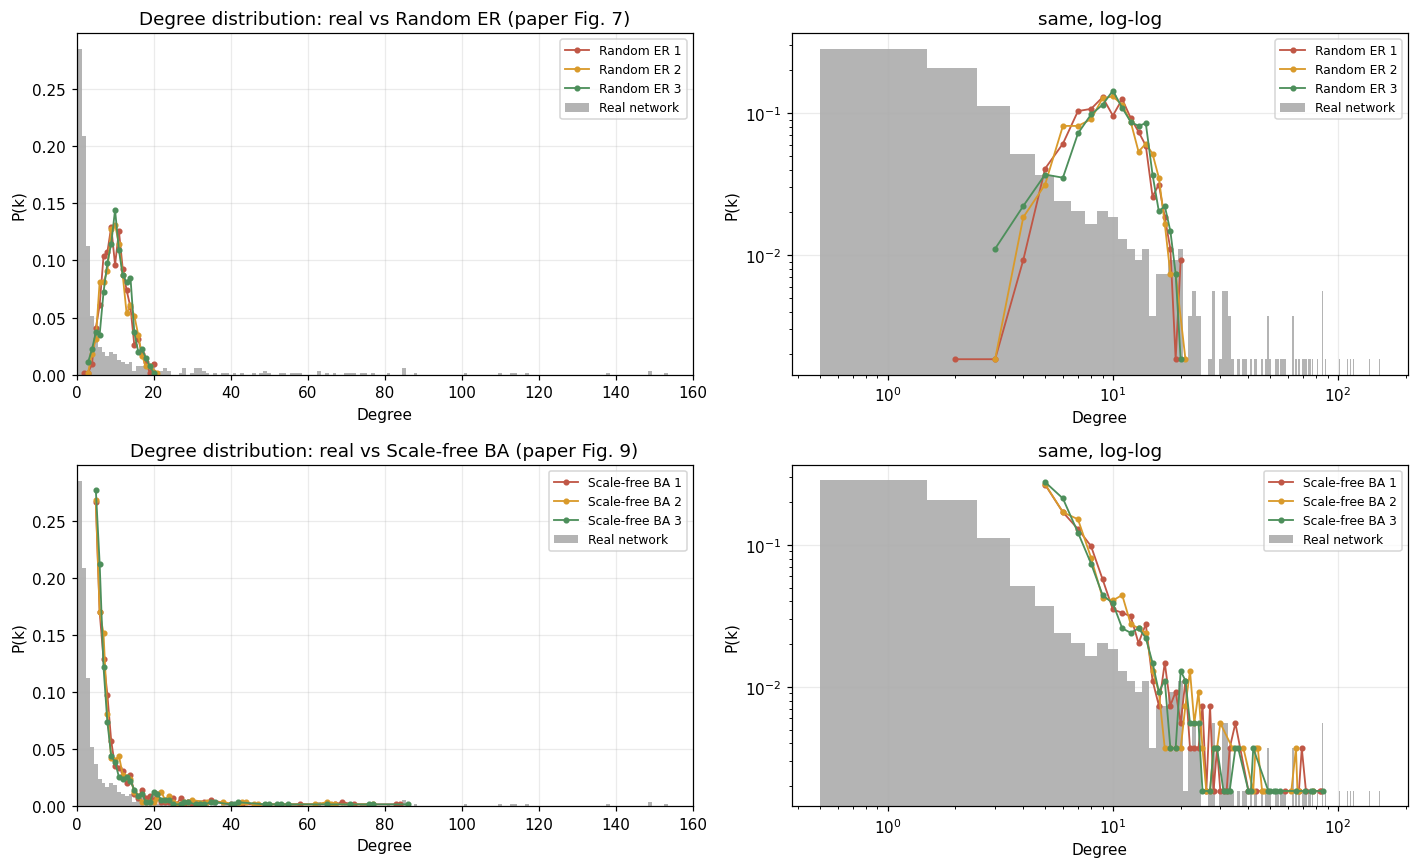

ER degrees range 2 to 21; BA degrees range 5 to 86; real: 1 to 153
share of nodes with degree 1:  real 28.5% | ER 0.0% | BA 0.0%


In [3]:
def pk(g):
    c = Counter(d for _, d in g.degree()); ks = np.array(sorted(c)); return ks, np.array([c[k] for k in ks]) / g.number_of_nodes()

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, (title, nulls, colors) in enumerate([("Random ER", er, [RED, ORANGE, GREEN]), ("Scale-free BA", ba, [RED, ORANGE, GREEN])]):
    kr, pr = pk(G)
    for col, scale in enumerate(["linear", "log"]):
        ax = axes[row, col]
        ax.bar(kr, pr, width=1.0, color=GREY, alpha=0.55, label="Real network")
        for i, g in enumerate(nulls):
            k_, p_ = pk(g); ax.plot(k_, p_, "o-", ms=3, lw=1.2, color=colors[i], label=f"{title} {i+1}")
        if scale == "linear":
            ax.set_xlim(0, 160); ax.set_title(f"Degree distribution: real vs {title} (paper Fig. {7 if row == 0 else 9})")
        else:
            ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title("same, log-log")
        ax.set_xlabel("Degree"); ax.set_ylabel("P(k)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

kb = sorted(set(d for g in ba for _, d in g.degree()))
print(f"ER degrees range {min(d for g in er for _, d in g.degree())} to {max(d for g in er for _, d in g.degree())}; "
      f"BA degrees range {min(d for g in ba for _, d in g.degree())} to {max(d for g in ba for _, d in g.degree())}; real: 1 to {max(d for _, d in G.degree())}")
print(f"share of nodes with degree 1:  real {np.mean([d == 1 for _, d in G.degree()]):.1%} | ER {np.mean([d == 1 for g in er for _, d in g.degree()]):.1%} | BA {np.mean([d == 1 for g in ba for _, d in g.degree()]):.1%}")

**Reading this.** ER degrees are binomial-like: a narrow bump around the mean of 10 and nothing above about 21, while the USFN spans 1 to 153. BA reproduces a heavy tail, but two differences are visible that the paper does not mention: **BA has no airport with fewer than 5 connections** (by construction, every new node brings 5 edges), whereas 28% of real airports have exactly one; and BA's largest hubs are much smaller than the real ones (77 to 86 in the three plotted graphs, 89 on average over 200 samples in Part B, against a real maximum of 153).

### A3. The networks themselves (Figs. 8 and 10)
The paper draws the real network next to each null, coloured by degree. Layouts are force-directed (spring), so only the overall look matters, not coordinates.

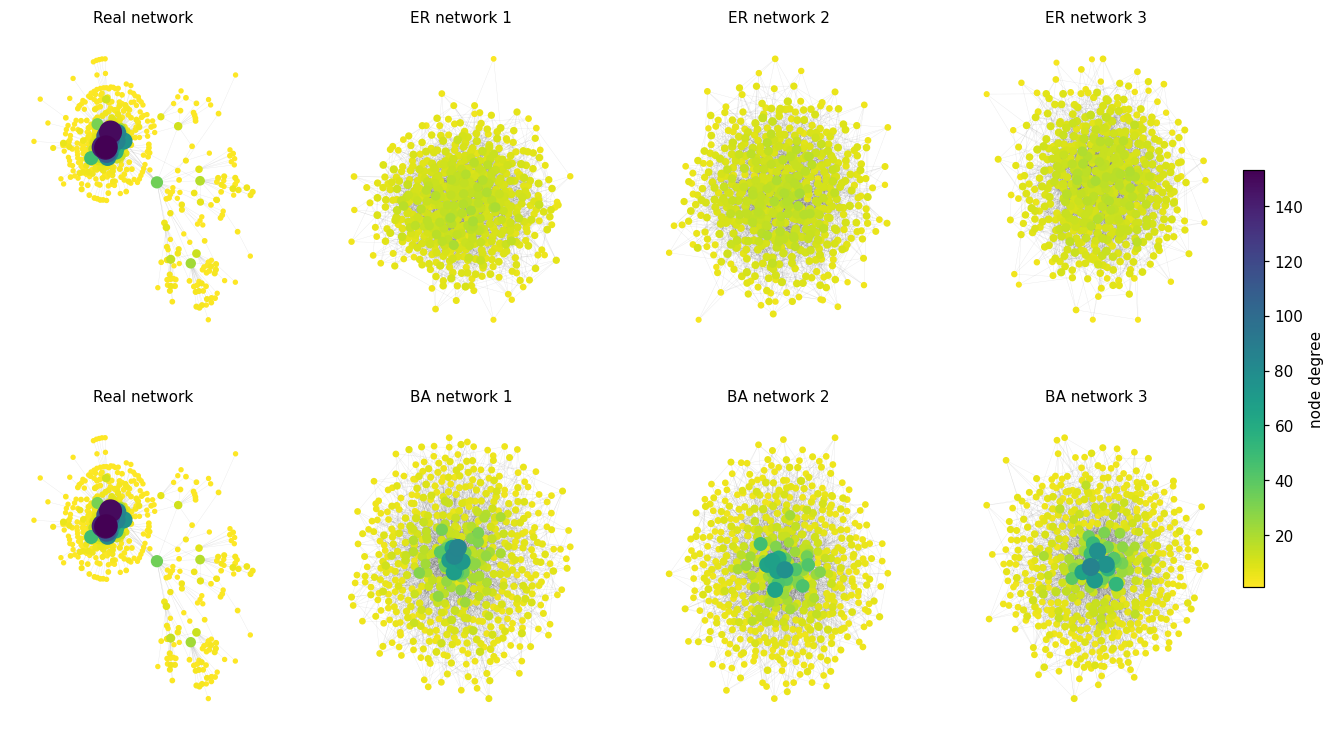

In [4]:
def draw(ax, g, title, pos, vmax=153):
    nx.draw_networkx_edges(g, pos, ax=ax, width=0.25, alpha=0.12, edge_color="#444444")
    nodes = sorted(g.nodes, key=g.degree)                       # draw big hubs last so they stay visible
    sc = nx.draw_networkx_nodes(g, pos, nodelist=nodes, node_size=[5 + 1.3 * g.degree(n) for n in nodes],
                                node_color=[g.degree(n) for n in nodes], cmap="viridis_r", vmin=1, vmax=vmax, ax=ax)
    ax.set_title(title, fontsize=10); ax.axis("off"); ax.grid(False)
    return sc

pos_real = nx.spring_layout(G, seed=7, iterations=80)
fig, axes = plt.subplots(2, 4, figsize=(17, 8.2))
for row, (nulls, name) in enumerate([(er, "ER"), (ba, "BA")]):
    sc = draw(axes[row, 0], G, "Real network", pos_real)
    for i, g in enumerate(nulls):
        draw(axes[row, i + 1], g, f"{name} network {i+1}", nx.spring_layout(g, seed=7, iterations=80))
fig.colorbar(sc, ax=axes, shrink=0.6, label="node degree", pad=0.01)
plt.show()

The real network has a few very large dark hubs inside a dense core, a halo of small airports (yellow) around it, and a separate **Alaskan lobe** attached to the main body by only a few thin links (the structure behind ANC's betweenness in M1). The ER graphs look like uniform fuzzballs where no node stands out, and the BA graphs have hubs but no lobes and a uniformly well-connected periphery (every node has at least 5 links). Neither null has any large-scale geography.

### A4. The summary comparison: clustering and path length

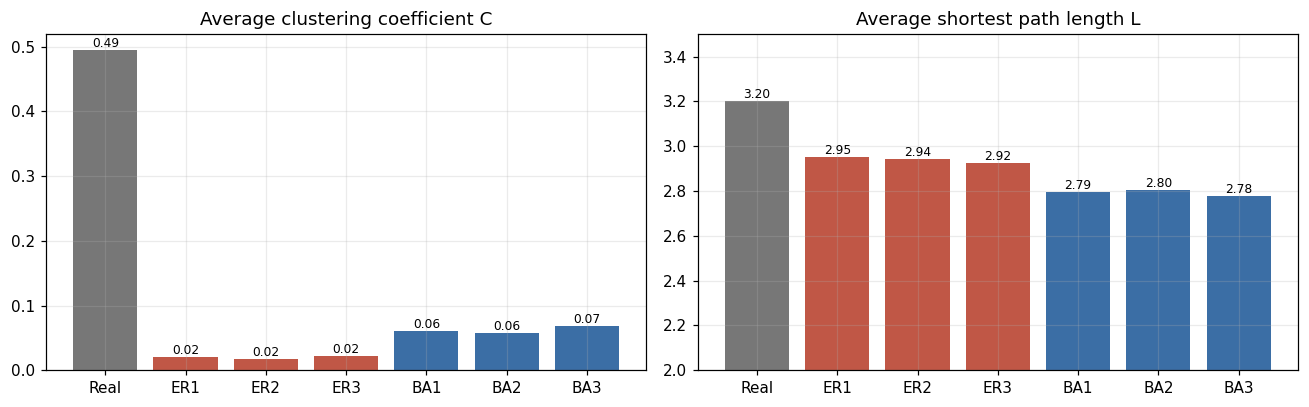

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
labels = ["Real", "ER1", "ER2", "ER3", "BA1", "BA2", "BA3"]
cols = [GREY, RED, RED, RED, BLUE, BLUE, BLUE]
for ax, key, title in [(axes[0], "C", "Average clustering coefficient C"), (axes[1], "L", "Average shortest path length L")]:
    vals = ours[key].values
    bars = ax.bar(labels, vals, color=cols)
    for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(title)
axes[1].set_ylim(2.0, 3.5)
plt.tight_layout(); plt.show()

This is the paper's evidence in one picture: the real network has about **25 times** the clustering of an ER graph and **8 times** that of a BA graph, but its paths are only about 8% (vs ER) to 15% (vs BA) *longer*. The paper reads this as proof of "meaningful community structure" and of an "economical design". Part A reproduced the paper's numbers; the question for the rest of the notebook is whether that reading is justified by comparing with only these three graphs.

## Part B. Adding error bars: 200 samples of each null model

Three graphs per model cannot say how variable a null is. We draw 200 ER and 200 BA graphs and add the degree-preserving null from Part C at the same time. For each real metric we report a **z-score** = (real - null mean) / null standard deviation; |z| above 3 is conventionally strong evidence that the real network is unlike the null.

In [6]:
N_SAMP = 200
all_pairs_km = nm.all_pairs_mean_km(G)
real_len = nm.edge_lengths_km(G, G)

rows = {"ER": [], "BA": [], "Degree-preserving": []}
len_stats = []
deg_real = dict(G.degree())
for s in range(N_SAMP):
    seed = 1000 + s
    rows["ER"].append(nm.fast_metrics(nm.er_like(N, M, seed)))
    rows["BA"].append(nm.fast_metrics(nm.ba_like(N, M, seed)))
    dp = nm.degree_preserving(G, seed)
    assert dict(dp.degree()) == deg_real                         # every airport keeps exactly its real degree
    rows["Degree-preserving"].append(nm.fast_metrics(dp))
    el = nm.edge_lengths_km(dp, G)
    len_stats.append({"mean": el.mean(), "median": np.median(el), "share_short": (el < 500).mean()})
    if s < 20:
        pooled = el if s == 0 else np.concatenate([pooled, el])
null = {k: pd.DataFrame(v) for k, v in rows.items()}
len_df = pd.DataFrame(len_stats)
print({k: len(v) for k, v in null.items()}, "samples | all degree-preserving samples keep the real degree sequence exactly")

{'ER': 200, 'BA': 200, 'Degree-preserving': 200} samples | all degree-preserving samples keep the real degree sequence exactly


In [7]:
metrics = [("C", "average clustering C"), ("transitivity", "transitivity"), ("L", "average path length L"), ("diameter", "diameter"),
           ("assortativity", "degree assortativity r"), ("max_degree", "largest degree"), ("share_degree1", "share of degree-1 airports")]

def cell(df, key, real_val):
    m, sd = df[key].mean(), df[key].std(ddof=1)
    if sd < 1e-12: return f"{m:.3f} (fixed)", "fixed"
    return f"{m:.3f} +/- {sd:.3f}", f"{(real_val - m) / sd:+.0f}"

tbl = []
for key, name in metrics:
    row = {"metric": name, "Real": f"{real[key]:.3f}"}
    for model in ["ER", "BA", "Degree-preserving"]:
        txt, z = cell(null[model], key, real[key]); row[model] = txt; row[f"z vs {model}"] = z
    tbl.append(row)
summary = pd.DataFrame(tbl)
summary.style.hide(axis="index")

metric,Real,ER,z vs ER,BA,z vs BA,Degree-preserving,z vs Degree-preserving
average clustering C,0.494,0.019 +/- 0.002,+301,0.062 +/- 0.005,+82,0.423 +/- 0.011,+7
transitivity,0.313,0.019 +/- 0.001,+209,0.048 +/- 0.002,+139,0.234 +/- 0.003,+23
average path length L,3.200,2.944 +/- 0.023,+11,2.791 +/- 0.016,+26,2.667 +/- 0.013,+42
diameter,7.000,5.020 +/- 0.140,+14,4.430 +/- 0.496,+5,5.460 +/- 0.557,+3
degree assortativity r,-0.341,-0.004 +/- 0.018,-19,-0.066 +/- 0.014,-20,-0.394 +/- 0.006,+9
largest degree,153.000,21.205 +/- 1.521,+87,89.345 +/- 12.697,+5,153.000 (fixed),fixed
share of degree-1 airports,0.285,0.000 +/- 0.001,+345,0.000 +/- 0.000,+900,0.285 (fixed),fixed


**Reading the table.** Against ER and BA, every structural metric of the real network is far outside the null range (|z| is at least 5 everywhere and in the tens to hundreds for most metrics), so the paper's conclusion that the USFN is not like either model is statistically unambiguous. The ER and BA samples are very stable (small standard deviations), which is why three graphs per model were enough to see the *size* of the gap, but not to say how reliable the gap is. The third column block is the interesting one and is the subject of Part C.

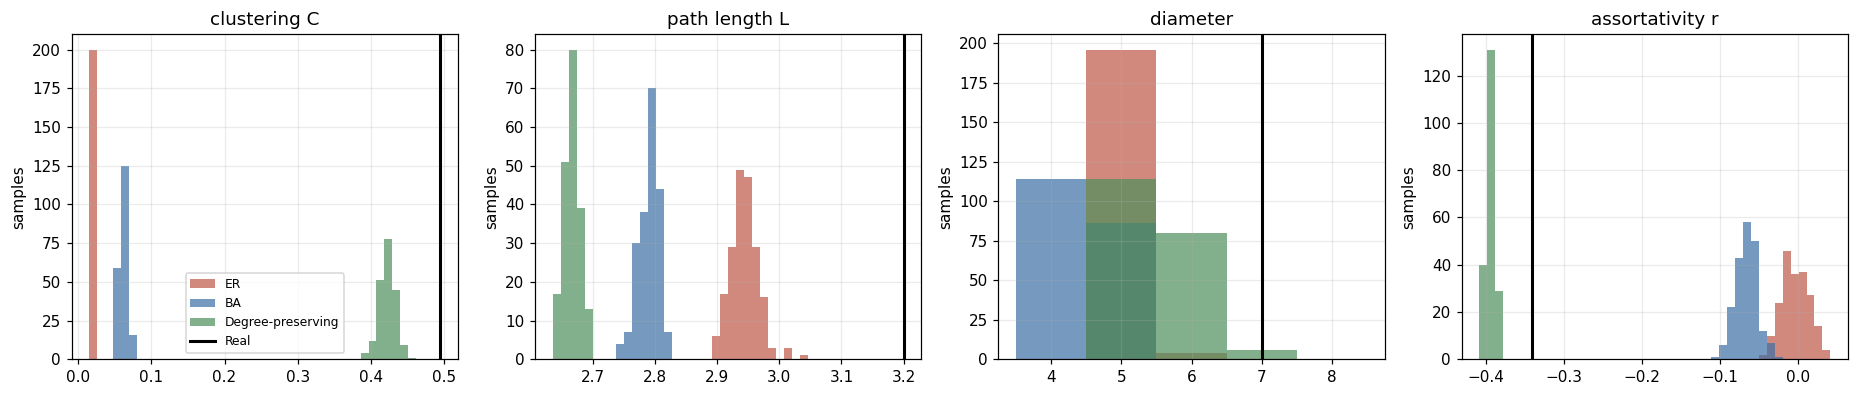

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.7))
for ax, (key, name) in zip(axes, [("C", "clustering C"), ("L", "path length L"), ("diameter", "diameter"), ("assortativity", "assortativity r")]):
    allv = np.concatenate([null[m][key].values for m in null] + [[real[key]]])
    bins = np.linspace(allv.min(), allv.max(), 45) if key != "diameter" else np.arange(3.5, 8.6, 1)
    for model, c in [("ER", RED), ("BA", BLUE), ("Degree-preserving", GREEN)]:
        ax.hist(null[model][key], bins=bins, alpha=0.7, color=c, label=model)
    ax.axvline(real[key], color="black", lw=2, label="Real")
    ax.set_title(name); ax.set_ylabel("samples")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

## Part C. A fairer null: keep the degrees, randomise the wiring

ER and BA have *different degree sequences* from the real network, so any difference conflates "who connects to whom" with "how many connections each airport has". The standard fix (Maslov and Sneppen) takes the **real** network and repeatedly swaps the endpoints of random pairs of edges, which keeps every airport's degree exactly as it is (verified in the sampling loop above) but destroys all other structure: geography, regions, hub-to-hub patterns. If the paper's evidence (high clustering, communities) really reflects structure beyond the degree sequence, it must survive this comparison.

In [9]:
C_r, C_er, C_ba, C_dp = real["C"], null["ER"].C.mean(), null["BA"].C.mean(), null["Degree-preserving"].C.mean()
T_r, T_er, T_dp = real["transitivity"], null["ER"].transitivity.mean(), null["Degree-preserving"].transitivity.mean()
L_r, L_er, L_dp = real["L"], null["ER"].L.mean(), null["Degree-preserving"].L.mean()
r_r, r_dp = real["assortativity"], null["Degree-preserving"].assortativity.mean()

share_C = (C_dp - C_er) / (C_r - C_er)
share_T = (T_dp - T_er) / (T_r - T_er)
print(f"Clustering C:  real {C_r:.3f} | ER {C_er:.3f} | BA {C_ba:.3f} | degree-preserving {C_dp:.3f}")
print(f"   -> the degree sequence alone produces {share_C:.0%} of the excess clustering over ER ((C_dp - C_ER) / (C_real - C_ER))")
print(f"Transitivity:  real {T_r:.3f} | ER {T_er:.3f} | degree-preserving {T_dp:.3f}   -> {share_T:.0%} of the excess is explained by degrees")
print(f"Path length:   real {L_r:.3f} | ER {L_er:.3f} | degree-preserving {L_dp:.3f}   -> real paths are {L_r / L_dp - 1:.0%} LONGER than the degree-matched null")
print(f"Assortativity: real {r_r:.3f} | degree-preserving {r_dp:.3f}   -> the negative degree correlation is largely a consequence of the degree sequence")
print(f"Share of 200 degree-preserving graphs that stayed connected: {null['Degree-preserving'].connected.mean():.0%}")

# half of the rewired graphs are disconnected (rewiring can pair degree-1 airports with each other); path statistics above
# average over reachable pairs only, so we re-check the key numbers on the connected samples alone
dpc = null["Degree-preserving"][null["Degree-preserving"].connected]
print(f"connected samples only (n = {len(dpc)}):  C = {dpc.C.mean():.3f}   L = {dpc.L.mean():.3f}   diameter = {dpc['diameter'].mean():.2f}   -> same conclusions as for all 200 samples (C {C_dp:.3f}, L {L_dp:.3f})")

Clustering C:  real 0.494 | ER 0.019 | BA 0.062 | degree-preserving 0.423
   -> the degree sequence alone produces 85% of the excess clustering over ER ((C_dp - C_ER) / (C_real - C_ER))
Transitivity:  real 0.313 | ER 0.019 | degree-preserving 0.234   -> 73% of the excess is explained by degrees
Path length:   real 3.200 | ER 2.944 | degree-preserving 2.667   -> real paths are 20% LONGER than the degree-matched null
Assortativity: real -0.341 | degree-preserving -0.394   -> the negative degree correlation is largely a consequence of the degree sequence
Share of 200 degree-preserving graphs that stayed connected: 50%
connected samples only (n = 100):  C = 0.421   L = 2.669   diameter = 5.48   -> same conclusions as for all 200 samples (C 0.423, L 2.667)


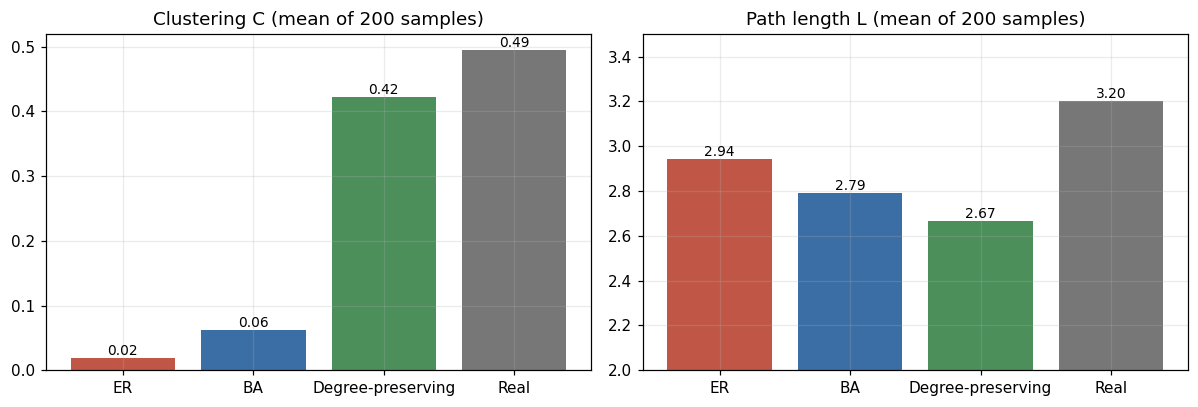

In [10]:
comp = pd.DataFrame({"model": ["ER", "BA", "Degree-preserving", "Real"], "C": [C_er, C_ba, C_dp, C_r], "L": [L_er, null["BA"].L.mean(), L_dp, L_r]})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, key, title in [(axes[0], "C", "Clustering C (mean of 200 samples)"), (axes[1], "L", "Path length L (mean of 200 samples)")]:
    b = ax.bar(comp.model, comp[key], color=[RED, BLUE, GREEN, GREY])
    for bb, v in zip(b, comp[key]): ax.text(bb.get_x() + bb.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
    ax.set_title(title)
axes[1].set_ylim(2.0, 3.5)
plt.tight_layout(); plt.show()

**Reading this.** This changes the paper's story in three ways.
1. **Most of the "excess" clustering is just the degree sequence.** The degree-matched null already reaches about 85% of the clustering gap between ER and the real network (0.42 vs 0.49, with ER at 0.02). The reason is hub-and-spoke structure: many small airports have only 2 or 3 connections, mostly to hubs, and the hubs are densely connected to each other, so neighbours-of-a-small-airport are often neighbours of each other. No communities or geography are needed to get this. The remaining excess is real (z of +7 for clustering and +23 for transitivity against the degree-preserving null) but modest (transitivity: real 0.31 vs 0.23).
2. **"Longer paths than random" holds, but "economical design" is not what it shows.** *Every* null model, including the degree-matched one (L about 2.67), has shorter paths than the real network. The real network is about 20% longer than the degree-matched baseline, and part of that excess is geographical (for example the chains of small Alaskan airports behind ANC found in M1).
3. **The degree sequence also explains the negative assortativity** found in M1: the degree-preserving null is at -0.39, even slightly more negative than the real -0.34. Simply having a few huge hubs and many small airports in a simple graph forces hubs to link to small airports.

## Part D. Does geography really constrain the network?

The paper's discussion says the network "is constrained by geography, policies, or other real-world constraints", but it never tests this. A direct test: compute the **great-circle length of every route** from the airport coordinates and compare with the degree-preserving null, which has the same degrees but ignores geography entirely, and with a fully random graph (whose edges join two random airports).

Mean route length:   real 1208 km | degree-preserving null 2348 +/- 17 km | random pair of airports 2977 km
Median route length: real 949 km | degree-preserving null 1833 km
Share of routes shorter than 500 km: real 27.1% | degree-preserving null 8.4%
z-score of the real mean route length against the degree-preserving null: -66


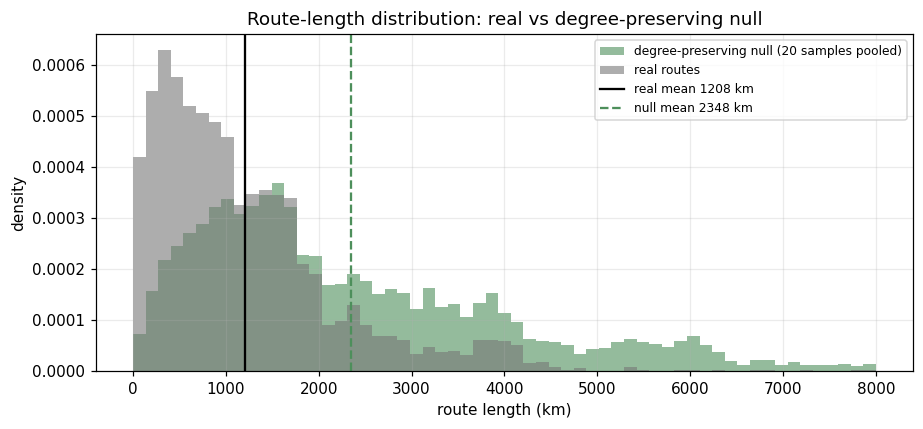

In [11]:
print(f"Mean route length:   real {real_len.mean():.0f} km | degree-preserving null {len_df['mean'].mean():.0f} +/- {len_df['mean'].std():.0f} km | random pair of airports {all_pairs_km:.0f} km")
print(f"Median route length: real {np.median(real_len):.0f} km | degree-preserving null {len_df['median'].mean():.0f} km")
print(f"Share of routes shorter than 500 km: real {(real_len < 500).mean():.1%} | degree-preserving null {len_df['share_short'].mean():.1%}")
z_len = (real_len.mean() - len_df['mean'].mean()) / len_df['mean'].std()
print(f"z-score of the real mean route length against the degree-preserving null: {z_len:.0f}")

fig, ax = plt.subplots(figsize=(8.5, 4))
bins = np.linspace(0, 8000, 60)
ax.hist(pooled, bins=bins, density=True, alpha=0.6, color=GREEN, label="degree-preserving null (20 samples pooled)")
ax.hist(real_len, bins=bins, density=True, alpha=0.6, color=GREY, label="real routes")
ax.axvline(real_len.mean(), color="black", lw=1.5, label=f"real mean {real_len.mean():.0f} km")
ax.axvline(len_df['mean'].mean(), color=GREEN, lw=1.5, ls="--", label=f"null mean {len_df['mean'].mean():.0f} km")
ax.set_xlabel("route length (km)"); ax.set_ylabel("density"); ax.set_title("Route-length distribution: real vs degree-preserving null"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading this.** Real routes are about **half as long** as the same degrees wired at random (about 1,210 km vs 2,350 km, and 2,980 km for a completely random pair of airports), and the difference is enormous in standard-deviation terms. So geography *does* matter strongly: it determines *where* an airport's connections go (mostly to nearby airports and to the hubs of its own region), even though it does not by itself create much *extra* clustering beyond what the hub-and-spoke degree sequence gives. This is evidence for the paper's claim that the paper itself never supplied.

## Part E. Verdict on the paper's claims

In [12]:
verdict = pd.DataFrame([
    ("Table 3 and Figs. 7 to 10 (ER and BA comparison)",
     "Reproduced: edge counts exactly; ER values to two decimals; BA values within 0.01 (null graphs are networkx generators with seeds 0, 1, 2)", "reproduced"),
    ("The USFN is non-random (clustering 0.49 vs 0.02, heavy-tailed vs binomial)",
     f"Confirmed with 200 samples: z for clustering is {summary.iloc[0]['z vs ER']} against ER and {summary.iloc[0]['z vs BA']} against BA", "supported"),
    ("ER paths are shorter, so the USFN was 'not designed for shortest distance but economical'",
     f"Numbers hold (L {L_r:.2f} vs {L_er:.2f}), but every null, including the degree-matched one ({L_dp:.2f}), has shorter paths; 'economical design' is not tested", "reproduced, interpretation unsupported"),
    ("High clustering shows communities that do not arise from random choice",
     f"The degree sequence alone produces about {share_C:.0%} of the clustering excess over ER; only the remainder (transitivity {T_r:.2f} vs {T_dp:.2f}) is extra structure", "largely explained by degrees"),
    ("BA replicates the heavy tail but not the clustering",
     "Clustering gap confirmed. The tail is only partly replicated: BA has no degrees below 5 (real: 28% have degree 1) and hubs about 40% smaller (89 vs 153 on average)", "partly supported"),
    ("The network is constrained by geography",
     f"Supported by a test the paper does not run: real routes average {real_len.mean():.0f} km vs {len_df['mean'].mean():.0f} km for degree-preserving rewiring", "supported"),
], columns=["paper's claim", "what we find", "status"])
verdict.style.hide(axis="index").format(escape="html").set_properties(subset=["paper's claim", "what we find"], **{"text-align": "left", "white-space": "normal"})

paper's claim,what we find,status
Table 3 and Figs. 7 to 10 (ER and BA comparison),"Reproduced: edge counts exactly; ER values to two decimals; BA values within 0.01 (null graphs are networkx generators with seeds 0, 1, 2)",reproduced
"The USFN is non-random (clustering 0.49 vs 0.02, heavy-tailed vs binomial)",Confirmed with 200 samples: z for clustering is +301 against ER and +82 against BA,supported
"ER paths are shorter, so the USFN was 'not designed for shortest distance but economical'","Numbers hold (L 3.20 vs 2.94), but every null, including the degree-matched one (2.67), has shorter paths; 'economical design' is not tested","reproduced, interpretation unsupported"
High clustering shows communities that do not arise from random choice,The degree sequence alone produces about 85% of the clustering excess over ER; only the remainder (transitivity 0.31 vs 0.23) is extra structure,largely explained by degrees
BA replicates the heavy tail but not the clustering,Clustering gap confirmed. The tail is only partly replicated: BA has no degrees below 5 (real: 28% have degree 1) and hubs about 40% smaller (89 vs 153 on average),partly supported
The network is constrained by geography,Supported by a test the paper does not run: real routes average 1208 km vs 2348 km for degree-preserving rewiring,supported


## Check against the paper

In [13]:
exp_edges = {"Random ER Network 1": 2767, "Random ER Network 2": 2777, "Random ER Network 3": 2832,
             "Scale-Free BA Network 1": 2680, "Scale-Free BA Network 2": 2680, "Scale-Free BA Network 3": 2680}
chk = t3.copy()
chk["edges ok"] = chk["edges paper"] == chk["edges ours"]
chk["C ok (within 0.01)"] = (chk["C paper"] - chk["C ours"]).abs() <= 0.0101
chk["L ok (within 0.01)"] = (chk["L paper"] - chk["L ours"]).abs() <= 0.0101
chk["exact to 2 decimals"] = (chk["C paper"] == chk["C ours"].round(2)) & (chk["L paper"] == chk["L ours"].round(2))
display(chk[["model", "edges ok", "C ok (within 0.01)", "L ok (within 0.01)", "exact to 2 decimals"]])

assert chk["edges ok"].all() and chk["C ok (within 0.01)"].all() and chk["L ok (within 0.01)"].all()
assert chk.loc[chk.model.str.contains("ER|Real"), "exact to 2 decimals"].all()          # ER and real match exactly
assert (abs((real["C"] - null["ER"].C.mean()) / null["ER"].C.std()) > 10) and (abs((real["C"] - null["BA"].C.mean()) / null["BA"].C.std()) > 10)
assert null["Degree-preserving"].C.mean() > null["ER"].C.mean() and null["Degree-preserving"].C.mean() < real["C"]
assert 0.7 < share_C < 1.0
assert null["Degree-preserving"].L.mean() < real["L"] and null["ER"].L.mean() < real["L"] and null["BA"].L.mean() < real["L"]
assert real_len.mean() < 0.7 * len_df["mean"].mean() and z_len < -10
assert abs(dpc.L.mean() - null["Degree-preserving"].L.mean()) < 0.05 and dpc.L.mean() < real["L"]      # robust to disconnected samples
print("All M4 assertions passed.")

,model,edges ok,C ok (within 0.01),L ok (within 0.01),exact to 2 decimals
0,Real Network,True,True,True,True
1,Random ER Network 1,True,True,True,True
2,Random ER Network 2,True,True,True,True
3,Random ER Network 3,True,True,True,True
4,Scale-Free BA Network 1,True,True,True,False
5,Scale-Free BA Network 2,True,True,True,True
6,Scale-Free BA Network 3,True,True,True,False


All M4 assertions passed.


## Summary and take-aways

- **Reproduced:** Table 3 and the degree-distribution and network comparisons match the paper: every edge count exactly, the ER values to two decimals, the BA values within 0.01. The paper's BA graphs use attachment parameter k = 5, and the graphs correspond to networkx generators with seeds 0, 1, 2.
- **The paper's conclusion (the USFN is not random and not BA) is solid** and stays solid with 200 samples (|z| in the tens or more), but it was shown with three graphs per model and no uncertainty.
- **The interpretation needs correcting.** A degree-matched null reaches about 85% of the clustering excess over ER, so most of the "meaningful community structure" evidence is the hub-and-spoke degree sequence itself; and every null has shorter paths than the real network, so "economical design" is not what that comparison shows (real paths are about 20% longer than the degree-matched baseline).
- **Geography matters, but in *where* edges go, not in global clustering:** real routes are about half as long as in a degree-preserving random rewiring (z far beyond -10), a test the paper's discussion implies but never runs.
- **Implication for M3 and beyond:** community structure should be judged against the degree-preserving null too. In M3 we will compare modularity of the Louvain communities with the modularity Louvain finds on degree-preserving random graphs.

**Next:** M3 (communities, Section 4.2) is still open; after that M5 reproduces the attack simulations.